In [3]:
!pip install seaborn matplotlib scikit-learn pandas numpy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler



In [5]:
# 1. Load data
df = pd.read_csv("spotify_tracks.csv")  # adjust filename as needed

# 2. Data Validation Check
print("Data Shape:", df.shape)
print("Missing values per column:\n", df.isnull().sum())
df = df.dropna()

# 3. Feature Selection
# Audio features suited for similarity calculation
feature_cols = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]
X = df[feature_cols]

# 4. Feature Scaling (Crucial for Euclidean distance in K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Data Shape: (114000, 21)
Missing values per column:
 Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


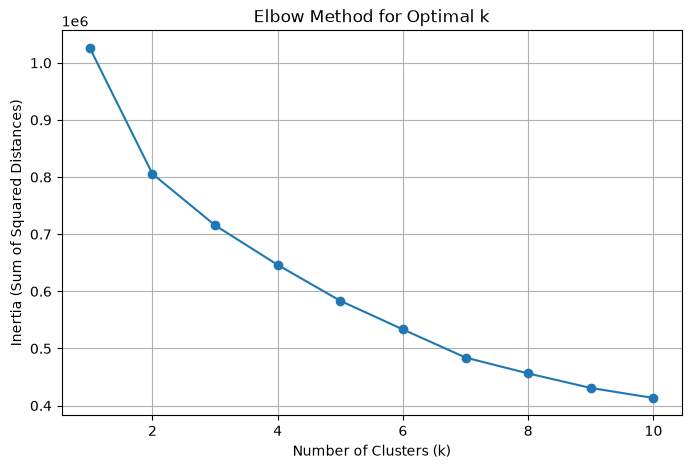

In [6]:
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker="o")
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Sum of Squared Distances)")
plt.grid(True)
plt.savefig("elbow_plot.png")
plt.show()

In [7]:
optimal_k = 4  # Set based on your elbow plot
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

# View mean feature values per cluster to understand what each cluster represents
cluster_summary = df.groupby("cluster")[feature_cols].mean()
print(cluster_summary)

# Identify example tracks for each cluster
for cluster_id in range(optimal_k):
    print(f"\n--- Cluster {cluster_id} Examples ---")
    sample_tracks = df[df["cluster"] == cluster_id][
        ["track_name", "artists"]
    ].head(3)
    print(sample_tracks)

         danceability    energy   loudness  speechiness  acousticness  \
cluster                                                                 
0            0.531258  0.743455  -7.636229     0.188580      0.346228   
1            0.456181  0.274523 -14.754676     0.051068      0.771991   
2            0.689274  0.687450  -6.837881     0.087299      0.256912   
3            0.484223  0.800772  -5.960819     0.077656      0.077386   

         instrumentalness  liveness   valence       tempo  
cluster                                                    
0                0.073021  0.734506  0.499336  120.723119  
1                0.324512  0.157239  0.290552  109.743132  
2                0.050048  0.162367  0.666864  117.900989  
3                0.207007  0.190334  0.330029  136.632090  

--- Cluster 0 Examples ---
               track_name           artists
51                透明だった世界     Motohiro Hata
73   You're Still The One       Bailey Jehl
343      A Month from Now  Rail Yard Ghos